# Reconstructing the primordial radius–period gap (Lee 2021/2022)

This notebook reconstructs the **primordial radius vs. orbital period distribution** carved
out purely by *late-stage* (gas-poor) gas accretion, using the **simple analytic model** of
Lee et al. (`lee2021.tex` / `lee2022.tex`). This corresponds to the `prim_RvP` figure
(dust-free accretion, fiducial parameters).

**Model summary**
- Underlying core-mass function: $dN/d\log M_{\rm core}\propto M_{\rm core}^{1-\xi}$, $\xi=0.7$, $M_{\rm core}\in[0.01,20]\,M_\oplus$.
- Orbital periods: $dN/d\log P = 0.52\,P^{-0.1}[1-e^{-(P/11.9\,{\rm d})^{2.4}}]$ (Petigura+18).
- Passive disk temperature: $T_{\rm disk}=1000\,{\rm K}\,f_T\,(a/0.1\,{\rm AU})^{-3/7}$.
- Dust-free envelope mass fraction (Lee+15 analytic scaling), capped by the maximally-cooled
  isothermal mass $M_{\rm iso}$.
- Envelope-mass-fraction → photometric radius via the Owen & Wu (2017) rcb procedure.

**Fiducial parameters** ( `prim_RvP` caption): $f_R=0.1$, $f_T=2$, $\xi=0.7$, $\rho_c=\rho_\oplus$,
$\tau_{\rm KH}=100$ Myr, accretion time $t=1$ Myr, and **disk gas depletion $f_{\rm dep}=10^{-3}$**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.stats import gaussian_kde

# --- load project matplotlib config (rcParams.txt is a name,value CSV) ---
_rc = pd.read_csv('../rcParams.txt')
for _, _row in _rc.iterrows():
    try:
        plt.rcParams[_row['name']] = eval(_row['value'])
    except Exception:
        plt.rcParams[_row['name']] = _row['value']

np.random.seed(42)

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (60)

In [2]:
# ---------------- physical constants (cgs) ----------------
G      = 6.674e-8       # cm^3 g^-1 s^-2
kB     = 1.380649e-16   # erg/K
mH     = 1.6726e-24     # g
sigSB  = 5.6704e-5      # erg cm^-2 s^-1 K^-4
Mearth = 5.972e27       # g
Rearth = 6.371e8        # cm
Msun   = 1.989e33       # g
Rsun   = 6.957e10       # cm
AU     = 1.496e13       # cm
yr     = 3.1557e7       # s
Teff_sun = 5772.0       # K

# ---------------- fiducial model parameters ----------------
fR     = 0.1            # outer-radius truncation factor
fT     = 2.0            # disk temperature coefficient
xi     = 0.7            # core-mass power-law slope (top-heavy)
Z      = 0.02           # envelope metallicity
mu     = 2.37           # mean molecular weight
gamma  = 7.0/5.0        # adiabatic index
tau_KH = 100.0e6 * yr   # Kelvin-Helmholtz cooling time
t_acc  = 1.0e6 * yr     # gas accretion duration (1 Myr)
f_dep  = 1.0e-3         # <-- disk gas depletion factor
rho_c_ratio = 1.0       # core density in units of rho_earth (prim_RvP uses rho_c = rho_earth)
Mstar  = Msun

# opacity law kappa = 10^C rho^alpha (kB/mu mH)^alpha Teq^(alpha+beta)  (Rogers+10, dust-free)
Cop, alpha, beta = -7.32, 0.68, 0.45
nab_ad = (gamma - 1.0) / gamma          # adiabatic gradient
Mc_min, Mc_max = 0.01, 20.0             # core mass range [Mearth]

In [3]:
# ---------------- disk / accretion model ----------------
def T_disk(a_cm):
    """Passive disk temperature [K]. a in cm."""
    return 1000.0 * fT * (a_cm / (0.1 * AU))**(-3.0/7.0)

def Sigma_gas(a_cm):
    """Local disk gas surface density [g/cm^2] (Chiang & Laughlin 2013, depleted)."""
    return 1.3e5 * f_dep * (a_cm / (0.2 * AU))**(-1.6)

def gcr_dustfree(Mc_g, a_cm):
    """Dust-free analytic envelope mass fraction M_env/M_core (Lee+15 scaling, eq df_accr)."""
    Td = T_disk(a_cm)
    Sg = Sigma_gas(a_cm)
    return (0.25 * fR
            * (Mc_g / (5.0 * Mearth))**1.1
            * (t_acc / (1.0e3 * yr))**0.4
            * (200.0 / Td)**1.5
            * (Sg / 4.0e5)**0.12
            * (0.02 / Z)**0.4
            * (mu / 2.37)**2.2)

def M_iso(Mc_g, a_cm):
    """Maximally-cooled isothermal envelope mass [g] (eq Miso)."""
    Td   = T_disk(a_cm)
    cs2  = kB * Td / (mu * mH)              # disk sound speed squared
    cs   = np.sqrt(cs2)
    Om   = np.sqrt(G * Mstar / a_cm**3)
    rho_disk = Sigma_gas(a_cm) * Om / cs
    Rcore = Rearth * (Mc_g / Mearth)**0.25
    RB    = G * Mc_g / cs2                  # Bondi radius
    RH    = a_cm * (Mc_g / (3.0 * Mstar))**(1.0/3.0)
    Rout  = fR * min(RB, RH)
    if Rout <= Rcore:
        return 0.0
    b = G * Mc_g / cs2
    integrand = lambda r: r**2 * np.exp(b * (1.0/r - 1.0/Rout))
    val, _ = quad(integrand, Rcore, Rout, limit=200)
    return 4.0 * np.pi * rho_disk * val

def envelope_fraction(Mc_g, a_cm):
    """Final M_env/M_core = min(analytic accretion, isothermal cap)."""
    menv_accr = gcr_dustfree(Mc_g, a_cm) * Mc_g
    menv = min(menv_accr, M_iso(Mc_g, a_cm))
    return menv / Mc_g

In [4]:
# ---------------- envelope mass fraction -> photometric radius ----------------
# Owen & Wu (2017) / Lee 2021 rcb procedure.
_exp = 1.0/(gamma - 1.0)        # = 2.5

def _In(n, x):
    """Structure integral I_n(x), x = Rrcb/Rcore."""
    lo = 1.0 / x
    f = lambda u: u**n * (1.0/u - 1.0)**_exp
    val, _ = quad(f, lo, 1.0, limit=200)
    return val

def planet_radius(Mc_g, a_cm, gcr):
    """Photometric radius [cm] for core mass Mc_g, distance a_cm, env. fraction gcr."""
    Rcore = Rearth * (Mc_g / Mearth)**0.25 * rho_c_ratio**(-1.0/3.0)
    Teq   = Teff_sun * (Rsun / a_cm)**0.5
    cs2   = kB * Teq / (mu * mH)

    # bare-core floor (eq. for min M_env/M_core, tau_KH=100 Myr)
    gcr_min = 4.4e-5 * (Mc_g/Mearth)**0.74 * (a_cm/(0.42*AU))**0.44
    if gcr <= gcr_min:
        return Rcore
    Menv = gcr * Mc_g

    def rho_rcb_eq2(x):  # explicit, from rearranging M_env (eq rhorcb2)
        return (Menv/(4.0*np.pi) * x**(-3.0+_exp) * Rcore**(-3.0+_exp)
                * (nab_ad*G*Mc_g/cs2)**(1.0/(1.0-gamma)) / _In(2, x))

    def rhs_eq1(x):      # RHS of rho_rcb^(1+alpha) (eq rhorcb1)
        return (64.0*np.pi*sigSB*mu*mH/(3.0*kB) * nab_ad * 10.0**(-Cop)
                * (mu*mH/kB)**alpha * Teq**(3.0-alpha-beta)
                * (_In(2, x)/_In(1, x)) * (tau_KH/Menv) * x * Rcore)

    def resid(x):
        return (1.0+alpha)*np.log(rho_rcb_eq2(x)) - np.log(rhs_eq1(x))

    try:
        x = brentq(resid, 1.0001, 200.0, maxiter=200)
    except ValueError:
        return Rcore
    if x < 1.05:                 # within Kepler 5% depth error -> bare core
        return Rcore

    Rrcb   = x * Rcore
    rho_rcb = rho_rcb_eq2(x)
    kappa  = 10.0**Cop * rho_rcb**alpha * (kB/(mu*mH))**alpha * Teq**(alpha+beta)
    gsurf  = G * Mc_g / Rrcb**2
    rho_ph = (2.0/3.0) * mu*mH*gsurf / (kB*Teq*kappa)
    Rphot  = Rrcb + np.log(rho_rcb/rho_ph) * kB*Teq/(mu*mH*gsurf)
    return Rphot

In [5]:
# ---------------- population synthesis ----------------
N = 4000

# core masses: dN/dlogM ~ M^(1-xi)  => dN/dM ~ M^(-xi); inverse-CDF sampling
U = np.random.rand(N)
p = 1.0 - xi
Mc = ((Mc_max**p - Mc_min**p) * U + Mc_min**p)**(1.0/p)   # [Mearth]

# orbital periods: dN/dlogP (Petigura+18); inverse-CDF on a grid
logP = np.linspace(np.log10(1.0), np.log10(300.0), 4000)
Pgrid = 10**logP
dNdlogP = 0.52 * Pgrid**(-0.1) * (1.0 - np.exp(-(Pgrid/11.9)**2.4))
cdf = np.cumsum(dNdlogP); cdf /= cdf[-1]
P = 10**np.interp(np.random.rand(N), cdf, logP)            # [days]
a = (G*Mstar*(P*86400.0)**2/(4.0*np.pi**2))**(1.0/3.0)     # [cm]

# evaluate model planet by planet
Rp = np.empty(N)
for i in range(N):
    Mc_g = Mc[i]*Mearth
    gcr  = envelope_fraction(Mc_g, a[i])
    Rp[i] = planet_radius(Mc_g, a[i], gcr) / Rearth        # [Rearth]

print(f'median Rp = {np.median(Rp):.2f} Re, range = [{Rp.min():.2f}, {Rp.max():.2f}] Re')
print(f'fraction < 1.8 Re (rocky): {np.mean(Rp < 1.8):.2f}')

median Rp = 1.94 Re, range = [0.32, 3.92] Re
fraction < 1.8 Re (rocky): 0.49


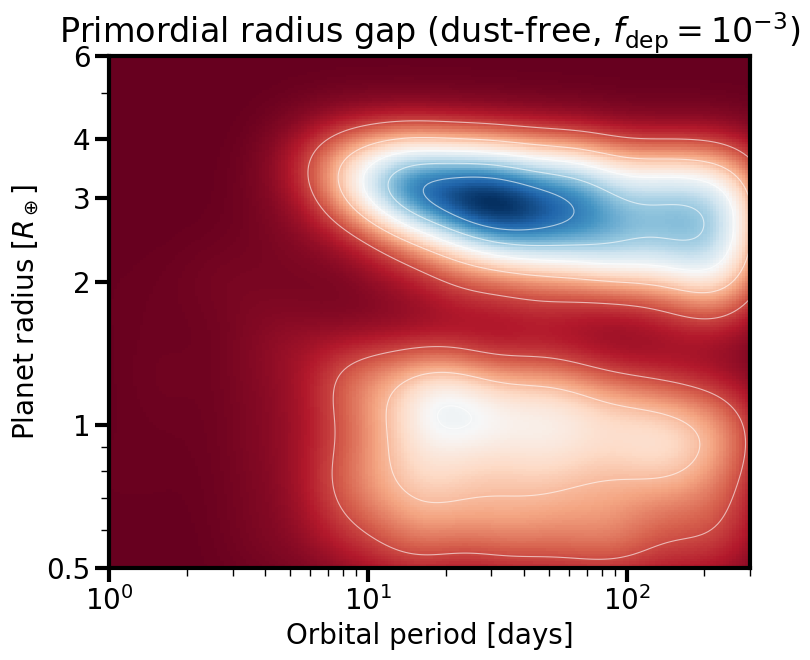

In [7]:
# ---------------- Figure: primordial radius vs orbital period ----------------
sel = (Rp > 0.5) & (Rp < 6) & (P > 1) & (P < 300)
xx, yy = np.log10(P[sel]), np.log10(Rp[sel])

# Gaussian KDE (Scott's rule), as in the paper
kde = gaussian_kde(np.vstack([xx, yy]))
Pg = np.linspace(np.log10(1), np.log10(300), 200)
Rg = np.linspace(np.log10(0.5), np.log10(6), 200)
XX, YY = np.meshgrid(Pg, Rg)
ZZ = kde(np.vstack([XX.ravel(), YY.ravel()])).reshape(XX.shape)

fig, ax = plt.subplots(figsize=(8, 7))
ax.pcolormesh(10**XX, 10**YY, ZZ, cmap='RdBu', shading='auto')
ax.contour(10**XX, 10**YY, ZZ, levels=6, colors='w', linewidths=0.8, alpha=0.6)
# ax.scatter(P[sel], Rp[sel], s=3, c='cyan', alpha=0.25, lw=0)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(1, 300); ax.set_ylim(0.5, 6)
ax.set_xlabel('Orbital period [days]')
ax.set_ylabel(r'Planet radius [$R_\oplus$]')
ax.set_yticks([0.5, 1, 2, 3, 4, 6])
ax.set_yticklabels(['0.5', '1', '2', '3', '4', '6'])
ax.set_title(r'Primordial radius gap (dust-free, $f_{\rm dep}=10^{-3}$)')
fig.tight_layout()
fig.savefig('../figures/lee2022_radius_period_gap.png', dpi=200, bbox_inches='tight')
plt.show()

Key takeaways from the late-stage gas-accretion model

1. The radius gap is carved at formation, not by later mass loss.
The headline result: gas accretion alone — during the gas-poor (f_dep≈10⁻³) late stage of disk evolution — produces the observed bimodal radius distribution. You don't need photoevaporation or core-powered mass
loss to create the gap (though those can further sculpt it). This is the paper's main claim against the mass-loss-only paradigm.

2. The gap comes from the maximally-cooled isothermal limit.
The physics is a single sharp nonlinearity: below 1–2 M⊕, a core cannot hold more than the isothermal envelope mass, which depends exponentially on core mass (M_iso ∝ exp(GM_core/c_s²R)). So a smooth core-mass
function maps to a bimodal radius distribution — small cores stay bare (~1 R⊕), cores above the threshold balloon to 2–3 R⊕. There's simply not enough dynamic range in core mass to populate the 1.5–2 R⊕ gap.
That's exactly the empty band in the figure.

3. The gap's negative period slope is a natural prediction.
Farther from the star → colder disk → larger Bondi radius → higher isothermal limit → the rocky-to-enveloped transition shifts to smaller core masses (hence smaller radii). This gives R_gap ∝ P^(−0.08 to
−0.09), matching van Eylen+18 and Martinez+19 — reproduced in the figure as the enveloped population dipping at long periods.

4. It accommodates a broad, bottom-heavy core-mass function.
Unlike mass-loss models, which require a sharply peaked core distribution at ~4–8 M⊕ (in tension with RV masses), this model works with a smooth power law (ξ=0.7) extending down into sub-Earth masses —
consistent with Marcy+14 RV follow-up and the lack of a fall-off below 1 R⊕ in Hsu+19.

5. Dust-free accretion is required.
The clean separation between the two populations only appears for dust-free envelopes — they accrete faster and have a weaker M_env–M_core dependence, which keeps the sub-Neptune peak narrow. Dusty accretion
smears the populations together.

6. Parameter sensitivities (the knobs).
- f_dep (disk depletion): mostly sets the abundance of large planets (≳3–4 R⊕); the gap itself is robust across 10⁻⁵–10⁻³.
- f_R (bound-radius truncation): smaller → narrower radius peak, closer to the gap.
- f_T (disk temperature): hotter → gap shifts to larger radii.
- ρ_c: fluffier cores push the valley to ~1.7–1.8 R⊕.

Bottom line: the morphology (peaks, valley, slope) is set primordially by where the isothermal cap intersects the accretion track; mass loss is a secondary tuning, not the origin. The figure you reconstructed
is the cleanest visual of that — a gap and period slope emerging purely from accretion physics.